In [1]:
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models


Read  the File

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

# Evaluate the impact of the detrending on the RFI peaks

In [4]:
for i,g in enumerate(datasets):
    spectrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))

    break

In [5]:
spectrum.shape

(634, 63877)

In [6]:
mask = (frequency > 2.75) & (frequency < 3.00)
mask1 = (frequency > 2.00) & (frequency < 2.007)
spectrum = spectrum[:,mask]
frequency=frequency[mask]

In [7]:
# Devide the data in different time blocks 
n_time, n_freq = spectrum.shape

block_size = 63

blocks1 = []

blocks1_det = []

for start in range(0, n_time - block_size + 1, block_size):
    end = start + block_size 
    block = spectrum[start:end, :]     # shape (63, 63877)


    # averarege the block and convert in [dB]
    #block_mean = 10*np.log10(np.nanmean(block**2, axis=0))
    blocks1.append(block)

    # # detrend the blocks
    # blocks_det = base_correction(frequency, block_mean)
    # blocks1_det.append(blocks_det)

    #break

# convert to an array
blocks1 = np.array(blocks1) 
#blocks1_det = np.array(blocks1_det) 

print(blocks1.shape)
print(blocks1)


(10, 63, 9362)
[[[228.9959  228.80453 228.9612  ... 224.84087 225.21898 224.88477]
  [229.1218  228.83994 228.66698 ... 224.93204 224.94629 225.00862]
  [229.21121 229.08415 229.06323 ... 225.17326 224.88045 225.2202 ]
  ...
  [228.90735 228.75333 228.91081 ... 224.74031 225.02637 224.73013]
  [228.68765 228.9363  229.16452 ... 225.14665 224.92612 224.88976]
  [229.1213  229.2505  228.94121 ... 225.07765 225.38339 225.0841 ]]

 [[228.7279  229.05867 229.13339 ... 224.93063 225.0157  224.94528]
  [228.87245 228.84384 228.90822 ... 225.03043 225.24263 224.80176]
  [229.00284 229.05869 229.06953 ... 225.00223 225.46933 225.06207]
  ...
  [228.91711 229.08435 229.08922 ... 225.14192 225.09427 225.08377]
  [229.06685 229.03183 229.0706  ... 225.27144 225.34036 225.18248]
  [228.93759 229.51524 229.06868 ... 225.07108 225.33446 224.91724]]

 [[228.55606 228.91685 228.90869 ... 224.8064  224.94873 225.16997]
  [229.24944 229.16617 229.15463 ... 225.08766 225.04593 225.06274]
  [229.13803 229.

In [8]:

for t,f in enumerate(blocks1):
        

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=frequency)
    bkg, params = baseline_fitter.asls(blocks1[0,t,:], lam=1e7, p=0.03)

    # Step 2: evaluate residual signal after baseline correction
    baseli_correction = blocks1[0,t,:] - bkg

    ## Relative Loss Function
    loss_func = ((baseli_correction-blocks1[0,t,:])/blocks1[0,t,:])*100 

    
    ## Relative Deterioration of the Spectral
    sigma_residual = np.sqrt(np.nanmean(baseli_correction**2))
    sigma_noise = np.sqrt(np.nanmean(bkg**2))

    deterioration = ((sigma_residual-sigma_noise)/sigma_noise)*100


    # fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # # -------------------------------
    # # Histogram 1: Loss Factor
    # # -------------------------------
    # ax[0].hist(loss_func, bins=100, alpha=0.7, edgecolor='black', label=f'$\mu= {np.mean(loss_func):.3f}, \sigma ={np.std(loss_func):.3f}$')
    # # ax[0].axvline(loss_opt, color='red', linestyle='--', linewidth=2,
    # #             label=f"Optimised = {loss_opt:.3f}")\
    # ax[0].set_title("Histogram of Loss Function")
    # ax[0].set_xlabel("Loss Factor")
    # ax[0].set_ylabel("Count")
    # ax[0].legend(fontsize=12)

    # # -------------------------------
    # # Histogram 2: Deterioration Factor
    # # -------------------------------
    # ax[1].hist(deterioration, bins=100, alpha=0.7, edgecolor='black', label=f'$\mu= {np.mean(deterioration):.3f}, \sigma ={np.std(deterioration):.3f}$')
    # # ax[1].axvline(det_opt, color='red', linestyle='--', linewidth=2,
    # #             label=f"Optimised = {det_opt:.3f}")
    # ax[1].set_title("Histogram of Deterioration Factors")
    # ax[1].set_xlabel("Deterioration Factor")
    # ax[1].legend(fontsize=12)

    # plt.tight_layout()
    # plt.show()


    break




In [9]:
baseli_correction

array([ 0.12869263, -0.0630188 ,  0.09327698, ..., -0.10514832,
        0.272995  , -0.061203  ], dtype=float32)

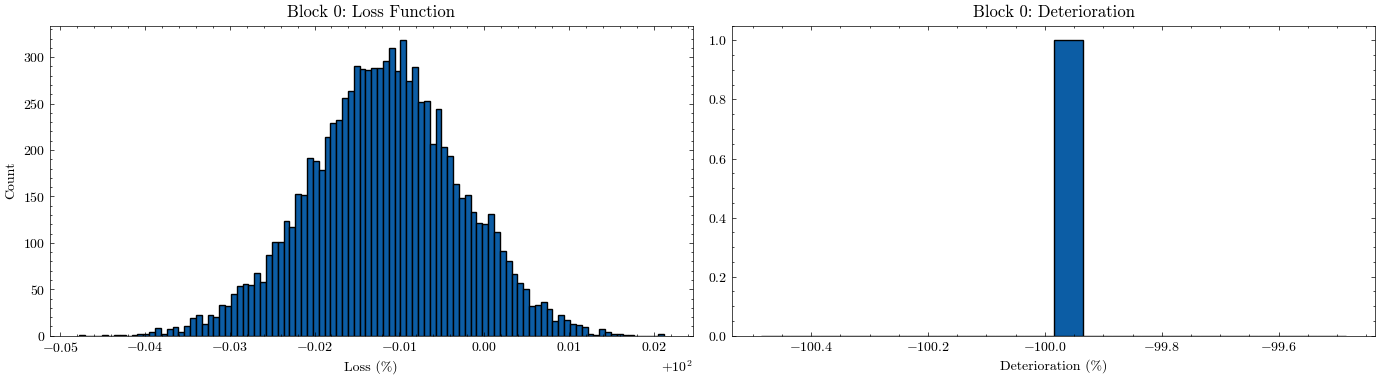

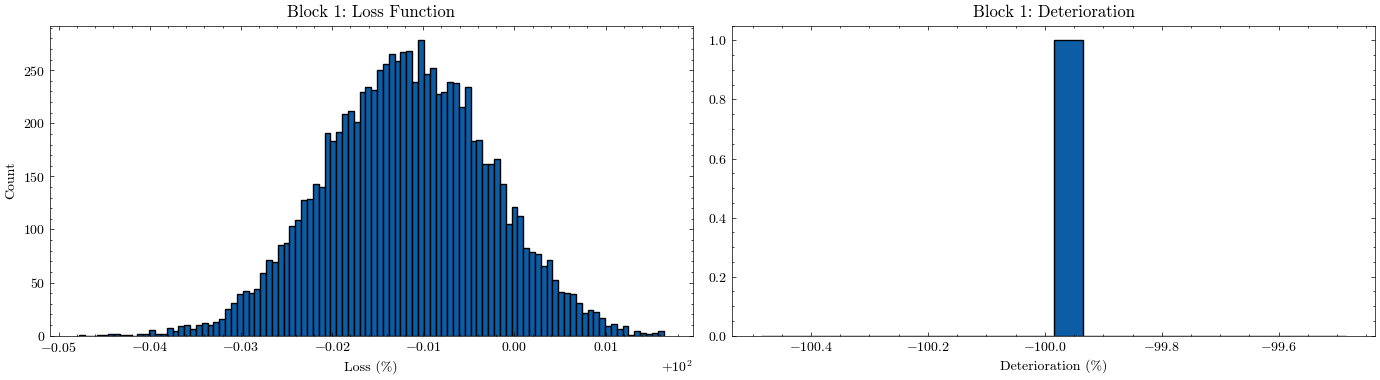

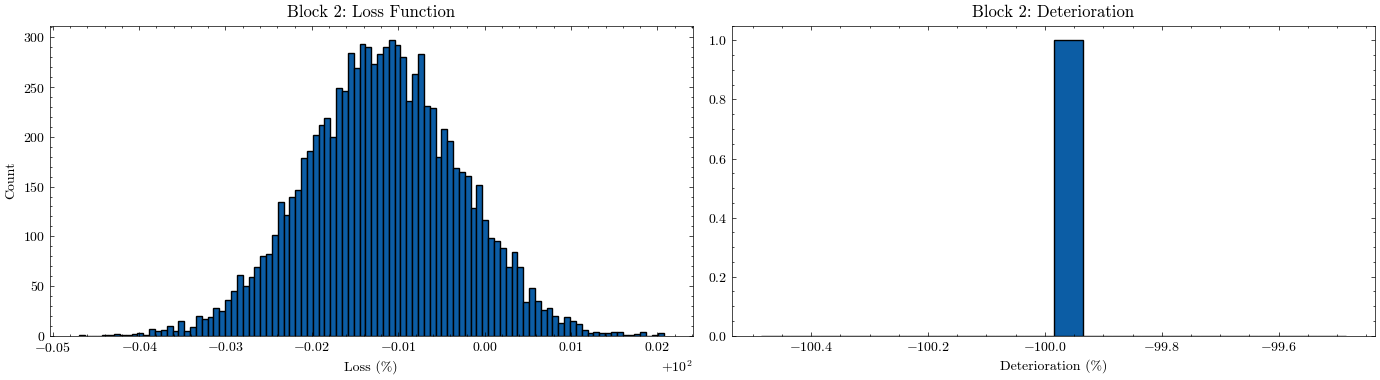

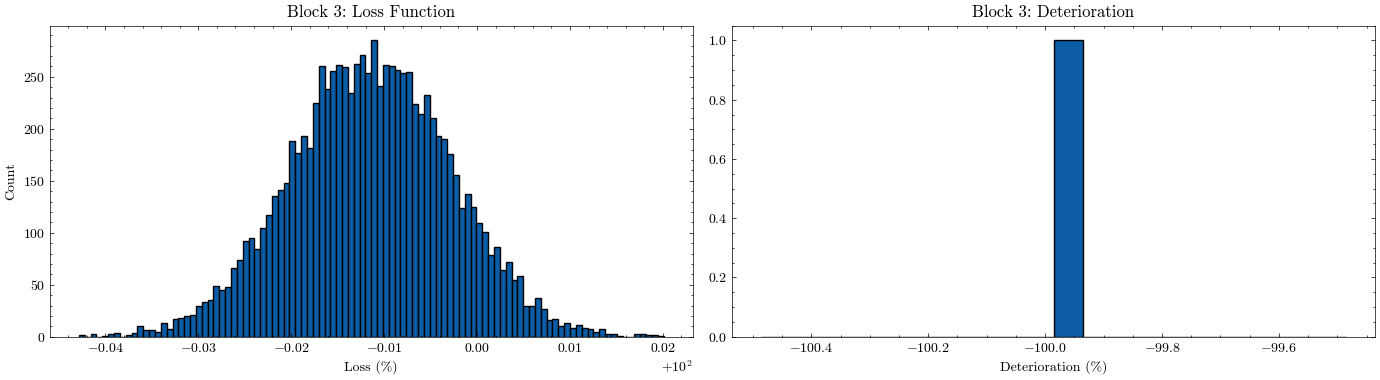

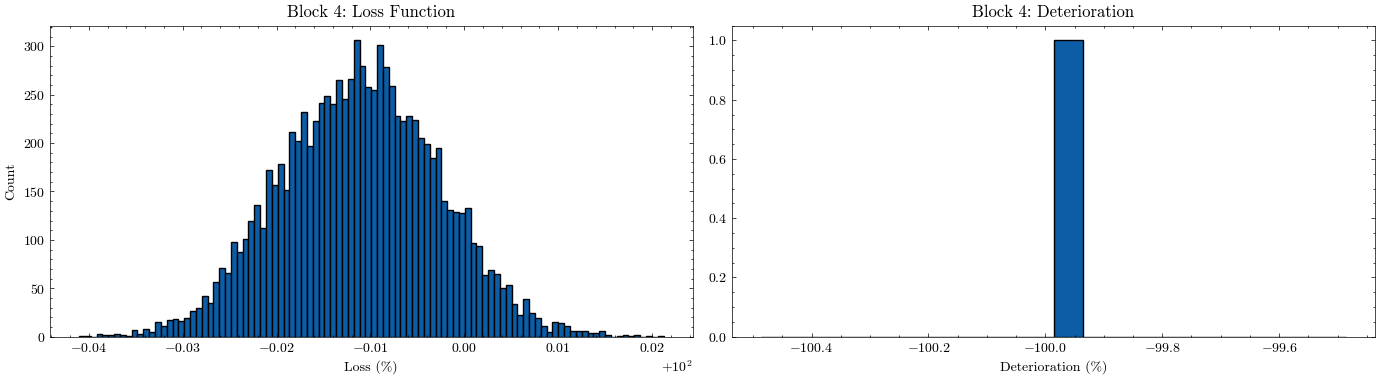

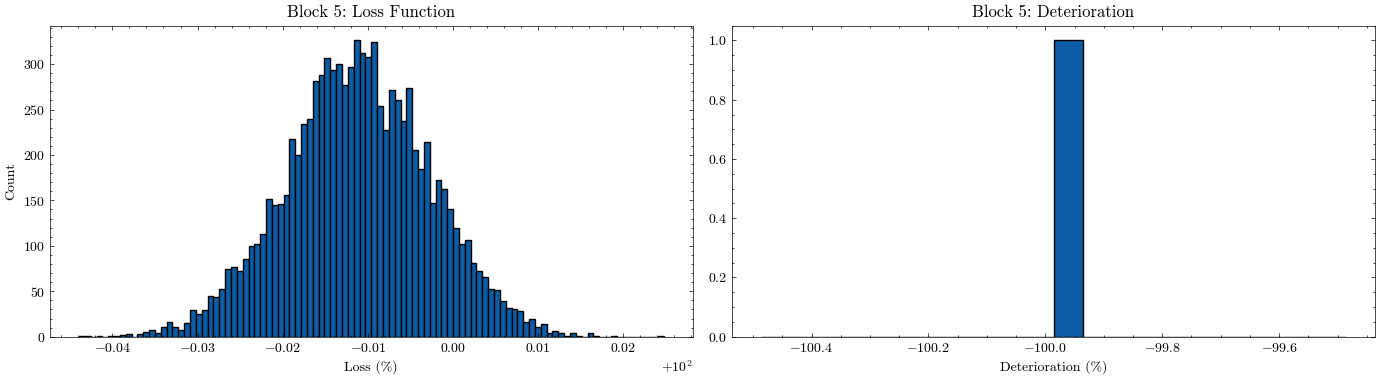

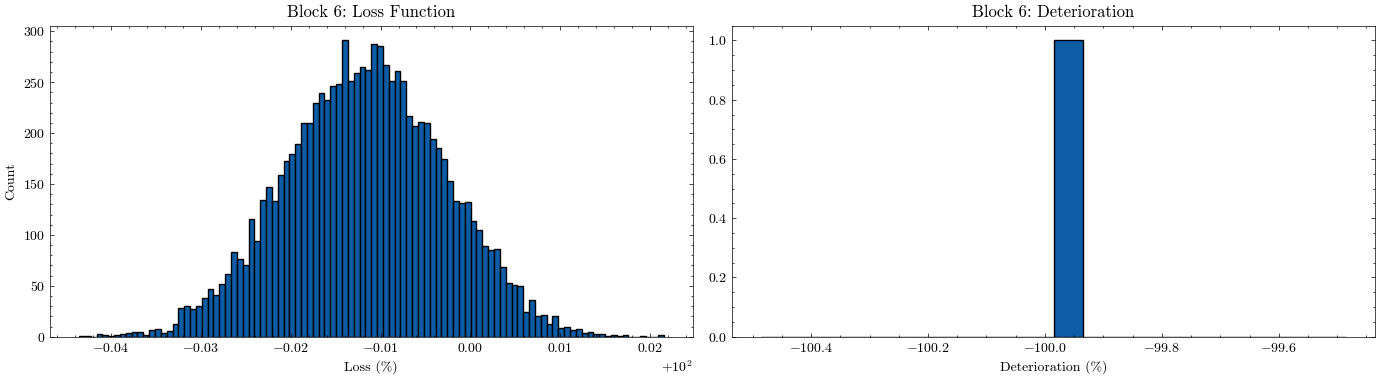

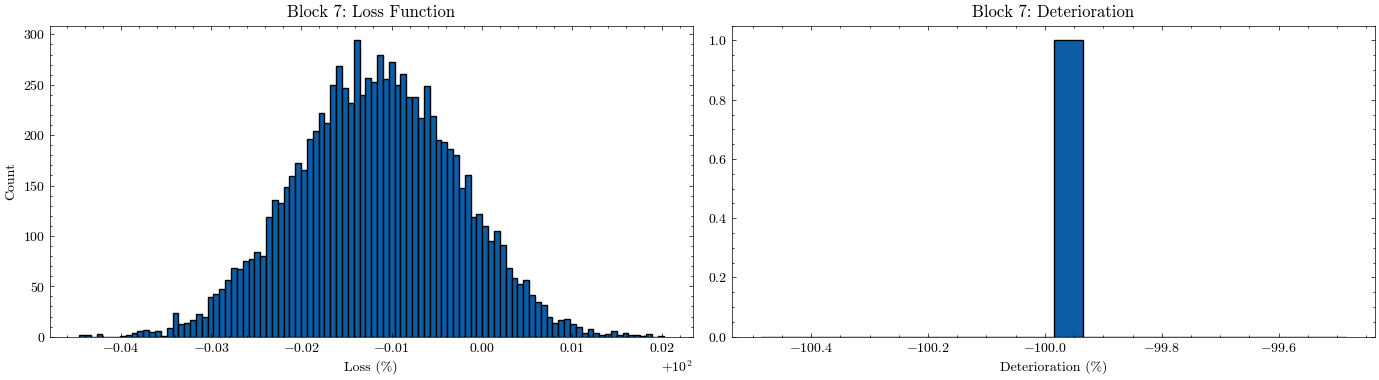

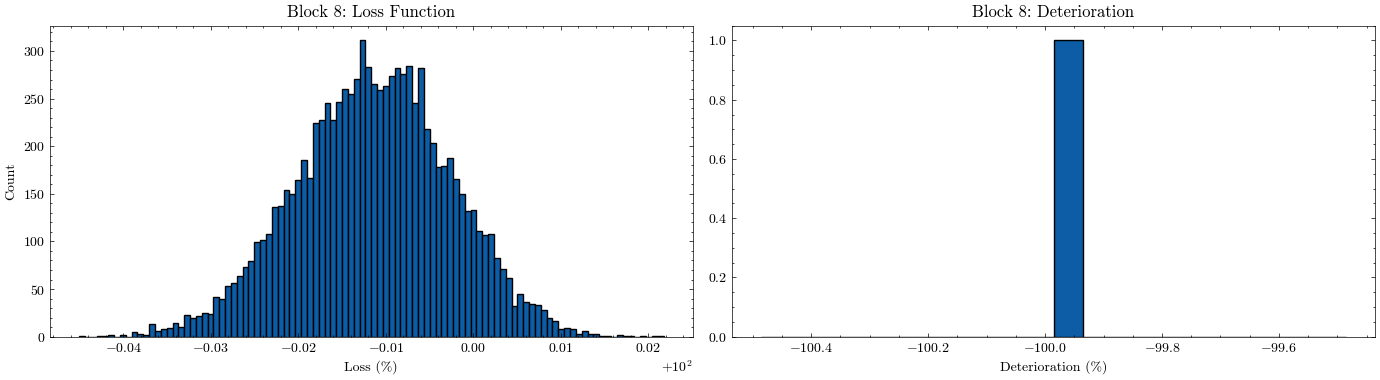

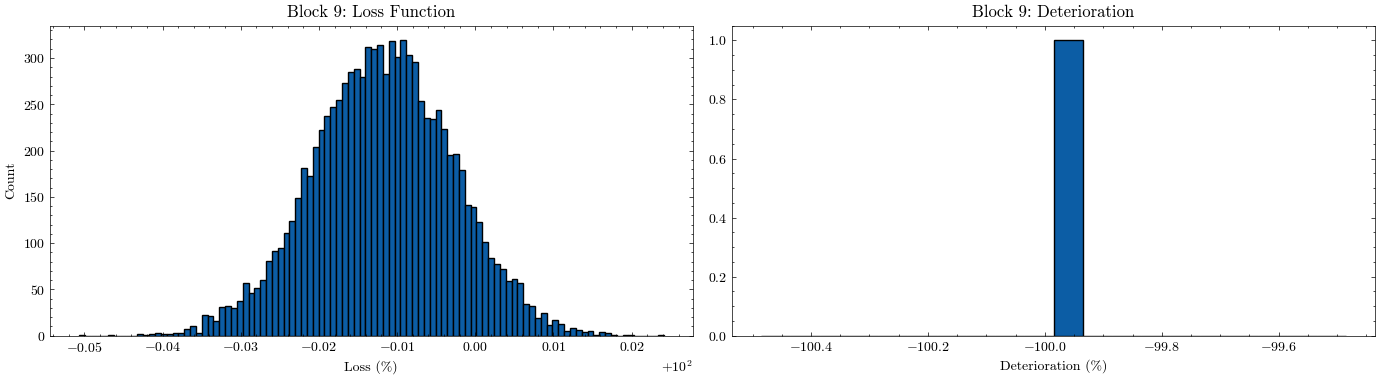

In [10]:


n_blocks = blocks1.shape[0]
loss_all = []
deterioration_all = []

for b in range(n_blocks):

    # ---------------------------
    # 1. Mean spectrum per block
    # ---------------------------
    block_mean = np.nanmean(blocks1[b, :, :], axis=0)   # shape (63877,)

    # ---------------------------
    # 2. Baseline fitting
    # ---------------------------
    baseline_fitter = Baseline(x_data=frequency)
    bkg, params = baseline_fitter.asls(block_mean, lam=1e7, p=0.03)

    # ---------------------------
    # 3. Baseline-corrected spectrum
    # ---------------------------
    corrected = block_mean - bkg

    # ---------------------------
    # 4. Relative Loss Function
    #    loss = (Fsim - Ffit)/Fsim * 100
    # ---------------------------
    loss = ((block_mean - corrected) / block_mean) * 100
    loss_all.append(loss)

    # ---------------------------
    # 5. Relative Deterioration
    #    deterioration = (σres - σnoi)/σnoi * 100
    # ---------------------------
    sigma_residual = np.sqrt(np.nanmean(corrected**2))   # rms of corrected spectrum
    sigma_noise = np.sqrt(np.nanmean(bkg**2))            # rms of baseline (noise estimate)

    deterioration = ((sigma_residual - sigma_noise) / sigma_noise) * 100
    deterioration_all.append(deterioration)

    # ---------------------------
    # 6. Plot histograms per block
    # ---------------------------
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    # Histogram of loss
    ax[0].hist(loss, bins=100, edgecolor='black', label=f'$\mu= {np.mean(loss):.3f}, \sigma ={np.std(loss):.3f}$')
    ax[0].set_title(f"Block {b}: Loss Function")
    ax[0].set_xlabel("Loss (%)")
    ax[0].set_ylabel("Count")

    # Histogram of deterioration (single value)
    ax[1].hist([deterioration], bins=20, edgecolor='black',label=f'$\mu= {np.mean(deterioration):.3f}, \sigma ={np.std(deterioration):.3f}$')
    ax[1].set_title(f"Block {b}: Deterioration")
    ax[1].set_xlabel("Deterioration (%)")

    plt.tight_layout()
    plt.show()


In [11]:
deterioration_all

[-99.98525977134705,
 -99.9851644039154,
 -99.98523592948914,
 -99.98563528060913,
 -99.98603463172913,
 -99.98599886894226,
 -99.98535513877869,
 -99.985271692276,
 -99.98555183410645,
 -99.98517632484436]

In [12]:

# loss_all → array of loss values for all channels (flattened)
# deterioration_all → array of deterioration values (one per channel or combined blocks)

loss_vals = np.array(loss_all)
deter_vals = np.array(deterioration_all).flatten

# Compute mean and sigma
mu_loss = np.mean(loss_vals)
sigma_loss = np.std(loss_vals)

mu_det = np.mean(deter_vals)
sigma_det = np.std(deter_vals)

# ------------------------------
# Plot
# ------------------------------
fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=False)

# ------------------------------
# Loss histogram
# ------------------------------
ax[0].hist(loss_vals, bins=60, density=True,
           color='lightgray', edgecolor='black')
ax[0].set_ylabel("Probability", fontsize=12)
ax[0].set_title("")  # optional
ax[0].text(0.02, 0.90,
           fr"$\mu={mu_loss:.1f},\ \sigma={sigma_loss:.1f}$",
           transform=ax[0].transAxes,
           fontsize=13)

# Match your example axis style
ax[0].set_xlim(-70, 30)
ax[0].set_xlabel("Loss (%)", fontsize=12)

# ------------------------------
# Deterioration histogram
# ------------------------------
ax[1].hist(deter_vals, bins=60, density=True,
           color='lightgray', edgecolor='black')
ax[1].set_ylabel("Probability", fontsize=12)
ax[1].set_xlabel("Deterioration (%)", fontsize=12)

ax[1].text(0.02, 0.90,
           fr"$\mu={mu_det:.1f},\ \sigma={sigma_det:.1f}$",
           transform=ax[1].transAxes,
           fontsize=13)

# Example-like x-axis limits
ax[1].set_xlim(-10, 10)

plt.tight_layout()
plt.show()


TypeError: unsupported operand type(s) for /: 'builtin_function_or_method' and 'int'